# ДЗ 1. Пять рекомендательных моделей на MovieTweetings

| Номер | Модель | Файл |
|---|---|---|
| 1 | Item-based kNN (косинус со сжатием) | `models/item_knn.py` |
| 2 | iALS для неявной обратной связи | `models/ials.py` |
| 3 | EASE | `models/ease.py` |
| 4 | Factorization Machine с метапризнаками, BPR | `models/fm.py` |
| 5 | iALS с собственным целевым сигналом | `models/ials_custom.py` |

Общие функции (загрузка, временное разбиение, метрики, top-k) — `models/utils.py`.

**Запуск**

```bash
pip install -r requirements.txt
jupyter notebook experiments.ipynb
```

Данные скачиваются первой ячейкой раздела 1 в папку `data/` (≈ 30 МБ) 

In [ ]:
import html
import platform
import time

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import scipy.sparse as sp
from IPython.display import display

from models.utils import (Popular, bootstrap_ci, download_movietweetings, evaluate, load_movietweetings,
                          make_stage, per_user_metrics)
from models.item_knn import ItemKNN
from models.ials import IALS
from models.ease import EASE
from models.fm import FactorizationMachine
from models.ials_custom import IALSCustomTarget

SEED = 42                                   # зерно для всех моделей и случайного поиска
K = 10                                      # длина рекомендаций
PRIMARY = f"NDCG@{K}"                       # основная метрика, выбрана до подбора
REL_THRESHOLD = 7                           # релевантно: оценка >= 7
MIN_ITEM_TRAIN = 5                          # каталог: фильмы с >= 5 оценками в train
T_VAL1 = pd.Timestamp("2016-07-01")         # начало первого окна валидации
T_VAL2 = pd.Timestamp("2017-01-01")         # начало второго окна валидации
T_TEST = pd.Timestamp("2017-07-01")         # начало test-окна
DATA_END = pd.Timestamp("2018-01-01")       # конец подвыборки (не включая)

np.random.seed(SEED)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print(f"Python {platform.python_version()} | numpy {np.__version__} | scipy {scipy.__version__} | "
      f"pandas {pd.__version__} | matplotlib {matplotlib.__version__}")

Python 3.13.5 | numpy 2.3.3 | scipy 1.16.2 | pandas 2.2.3 | matplotlib 3.10.6


## 1. Данные

**MovieTweetings** — оценки фильмов из твитов вида «I rated *Logan* 8/10 #IMDb». Пользователь ставит оценку на IMDb, и она автоматически публикуется в Twitter.

- Первоисточник: репозиторий авторов датасета, https://github.com/sidooms/MovieTweetings
- Способ получения: файлы `latest/ratings.dat` и `latest/movies.dat` из коммита [`44c525d`](https://github.com/sidooms/MovieTweetings/tree/44c525d0c766944910686c60697203cda39305d6). Вручную: `git clone https://github.com/sidooms/MovieTweetings`, `git checkout 44c525d`, скопировать `latest/ratings.dat` и `latest/movies.dat` в `data/`.

| Файл | Поле | Смысл |
|---|---|---|
| `ratings.dat` | `user_id` | анонимизированный пользователь Twitter |
| | `item_id` | IMDb-идентификатор фильма (число без префикса `tt`) |
| | `rating` | оценка по шкале IMDb, 1–10 |
| | `ts` | время твита, unix time (UTC) |
| `movies.dat` | `title` | название и год выпуска, например `Logan (2017)` |
| | `genres` | жанры IMDb через вертикальную черту |

**Взаимодействие** — пользователь оценил фильм в момент `ts`. Значит, он его посмотрел; значение оценки говорит, понравился ли фильм

**Что рекомендуем.** В момент $t_{rec}$ каждому пользователю — 10 фильмов, которые он раньше не оценивал

**Что считаем релевантным.** Фильм, который пользователь после $t_{rec}$ (в окне оценки) посмотрел и оценил на **7 и выше**. На шкале IMDb 7 означает «хорошо». Фильм с оценкой ниже 7 пользователь посмотрел, но он ему не понравился, поэтому попаданием такая рекомендация не считается. Критерий общий для всех моделей и не зависит от того, на каком таргете модель обучалась.

In [2]:
download_movietweetings("data")
ratings_raw, movies_raw = load_movietweetings("data")
print(f"ratings.dat: {len(ratings_raw):,} оценок, {ratings_raw.user_id.nunique():,} пользователей, "
      f"{ratings_raw.item_id.nunique():,} фильмов")
print(f"movies.dat:  {len(movies_raw):,} строк")
display(ratings_raw.head(3), movies_raw.head(3))

ratings.dat: OK (26.3 MB, sha256 совпадает)
movies.dat: OK (1.9 MB, sha256 совпадает)
ratings.dat: 921,398 оценок, 71,707 пользователей, 38,013 фильмов
movies.dat:  38,018 строк


,user_id,item_id,rating,ts
0,1,114508,8,1381006850
1,2,499549,9,1376753198
2,2,1305591,8,1376742507


,item_id,title,genres
0,8,Edison Kinetoscopic Record of a Sneeze (1894),Documentary|Short
1,10,La sortie des usines Lumière (1895),Documentary|Short
2,12,The Arrival of a Train (1896),Documentary|Short


## 2. EDA и подготовка данных

### Пропуски, дубликаты, аномалии

In [3]:
quality = pd.Series({
    "пропуски в ratings.dat": int(ratings_raw.isna().sum().sum()),
    "полные дубликаты строк": int(ratings_raw.duplicated().sum()),
    "повторные пары (user, item)": int(ratings_raw.duplicated(["user_id", "item_id"]).sum()),
    "оценка 0 (вне шкалы IMDb 1–10)": int((ratings_raw.rating == 0).sum()),
    "оценённые фильмы, которых нет в movies.dat": int((~ratings_raw.item_id.isin(movies_raw.item_id)).sum()),
    "пропуски жанров в movies.dat": int(movies_raw.genres.isna().sum()),
    "повторные item_id в movies.dat": int(movies_raw.item_id.duplicated().sum()),
    "названия с HTML-сущностями (&amp;, &x27;, ...)": int(movies_raw.title.str.contains(r"&[#a-zA-Z0-9]+;").sum()),
}).to_frame("количество")
display(quality)
display(movies_raw[movies_raw.item_id.duplicated(keep=False)].sort_values("item_id"))

,количество
пропуски в ratings.dat,0
полные дубликаты строк,0
"повторные пары (user, item)",0
оценка 0 (вне шкалы IMDb 1–10),281
"оценённые фильмы, которых нет в movies.dat",0
пропуски жанров в movies.dat,54
повторные item_id в movies.dat,5
"названия с HTML-сущностями (&amp;, &x27;, ...)",309


,item_id,title,genres
8456,106519,Carlito's Way (1993),NaN
8457,106519,Carlito's Way (1993),Crime|Drama|Thriller
18738,1361336,Tom and Jerry (2021),Animation|Adventure|Comedy|Family
18739,1361336,Tom and Jerry (2021),Animation|Adventure|Comedy|Family
22283,1979376,Toy Story 4 (2019),Animation|Adventure|Comedy|Family|Fantasy
22284,1979376,Toy Story 4 (2019),Animation|Adventure|Comedy|Family|Fantasy
29745,4160708,Don't Breathe (2016),Crime|Horror|Thriller
29746,4160708,Don&x27;t Breathe (2016),Crime|Horror|Thriller
36642,9620292,Promising Young Woman (2020),NaN
36643,9620292,Promising Young Woman (2020),Comedy|Crime|Drama|Thriller


Пропусков в оценках, повторных строк и повторных пар (пользователь, фильм) нет: каждую пару в данных оценивают один раз. Оценка 0 лежит вне шкалы IMDb, таких строк 281, их удаляем. В `movies.dat` пять `item_id` записаны дважды, и в двух случаях у одной из копий нет жанров; оставляем копию с жанрами. Оставшимся фильмам без жанров ставим жанр `Unknown`. HTML-сущности в названиях раскодируем, а год выпуска извлекаем из названия.

In [4]:
ratings = ratings_raw[ratings_raw.rating.between(1, 10)].copy()
ratings["dt"] = pd.to_datetime(ratings.ts, unit="s")

movies = (movies_raw.assign(has_genres=movies_raw.genres.notna())
          .sort_values(["item_id", "has_genres"], ascending=[True, False])
          .drop_duplicates("item_id").drop(columns="has_genres").reset_index(drop=True))
movies["genres"] = movies.genres.fillna("Unknown")
movies["title"] = movies.title.str.replace("&x27;", "'", regex=False).map(html.unescape)
movies["year"] = movies.title.str.extract(r"\((\d{4})\)\s*$")[0].astype(float)
print(f"после очистки: {len(ratings):,} оценок; фильмов в справочнике: {len(movies):,}, "
      f"без года выпуска: {movies.year.isna().sum()}")

после очистки: 921,117 оценок; фильмов в справочнике: 38,013, без года выпуска: 0


### Оценки и их динамика во времени

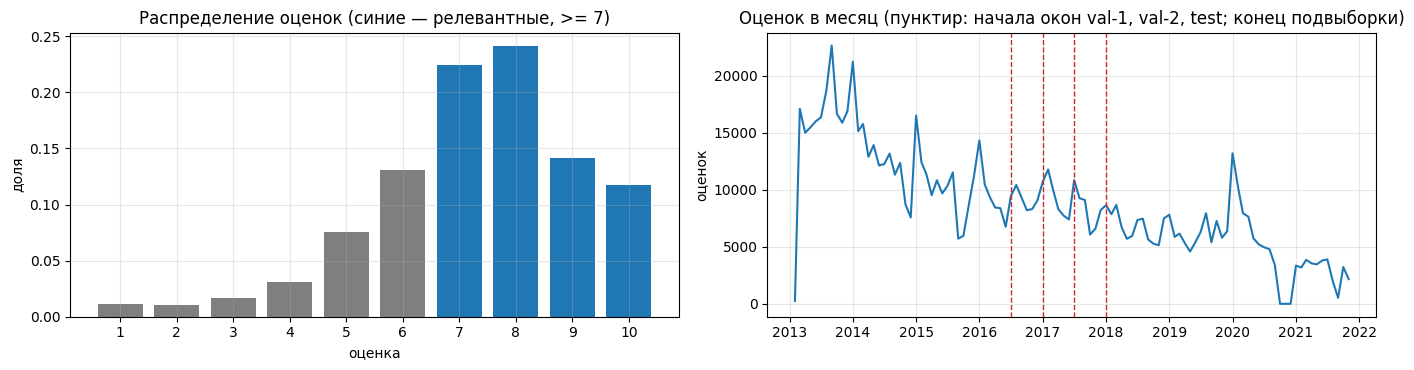

средняя оценка 7.31, медиана 8, доля оценок >= 7: 72.4%


dt,2013,2014,2015,2016,2017,2018,2019,2020,2021
оценок за год,170778,156323,123619,112413,105937,81842,74146,63089,32970


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
share = ratings.rating.value_counts(normalize=True).sort_index()
axes[0].bar(share.index, share.values, color=["tab:gray" if r < REL_THRESHOLD else "tab:blue" for r in share.index])
axes[0].set(title="Распределение оценок (синие — релевантные, >= 7)", xlabel="оценка", ylabel="доля", xticks=range(1, 11))
monthly = ratings.set_index("dt").rating.resample("MS").size()
axes[1].plot(monthly.index, monthly.values)
for t in (T_VAL1, T_VAL2, T_TEST, DATA_END):
    axes[1].axvline(t, color="tab:red", ls="--", lw=1)
axes[1].set(title="Оценок в месяц (пунктир: начала окон val-1, val-2, test; конец подвыборки)", ylabel="оценок")
plt.tight_layout()
plt.show()

print(f"средняя оценка {ratings.rating.mean():.2f}, медиана {ratings.rating.median():.0f}, "
      f"доля оценок >= {REL_THRESHOLD}: {(ratings.rating >= REL_THRESHOLD).mean():.1%}")
display(ratings.groupby(ratings.dt.dt.year).size().rename("оценок за год").to_frame().T)

Оценки смещены вверх: медиана 8, оценку 7 и выше получают около 72% фильмов. Это обычная картина для явной обратной связи: люди в основном смотрят то, что заранее ожидают оценить хорошо. Порог 7 отделяет «понравилось» (оценки 7–10) от «посмотрел, но не понравилось» (1–6).

Поток оценок со временем затухает: около 170 тыс. в 2013 году, около 106 тыс. в 2017-м и около 33 тыс. за неполный 2021-й.

**Подвыборка.** Берём все оценки с начала сбора (28.02.2013) по 31.12.2017, то есть **первые пять лет**. Почему так:
1. Окна валидации и теста по полгода должны содержать достаточно тёплых пользователей с релевантными фильмами. В 2016–2017 годах это 3,5–4 тыс. пользователей на окно, а в 2021-м было бы меньше полутора тысяч, и оценки метрик получились бы шумными.
2. Вычисления: EASE обращает матрицу «фильм x фильм», и на всех годах каталог был бы больше.

Отбор воспроизводим: это фильтр `ts < 2018-01-01`.

Фильтрацию по активности (k-core) на всей выборке **не делаем**: она использует будущие взаимодействия, ведь пользователь может пройти порог только за счёт тестовых оценок. Каталог и тёплых пользователей определяем по train каждого этапа, только по прошлому.

In [6]:
df = ratings[ratings.dt < DATA_END].reset_index(drop=True)
n_users, n_items = df.user_id.nunique(), df.item_id.nunique()
volume = pd.DataFrame(
    [[len(ratings_raw), ratings_raw.user_id.nunique(), ratings_raw.item_id.nunique()],
     [len(ratings), ratings.user_id.nunique(), ratings.item_id.nunique()],
     [len(df), n_users, n_items]],
    index=["исходные данные", "после очистки", "подвыборка 28.02.2013–31.12.2017 (итог)"],
    columns=["взаимодействий", "пользователей", "фильмов"])
display(volume)
print(f"разреженность итоговой матрицы: {1 - len(df) / (n_users * n_items):.4%} "
      f"(заполнено {len(df) / (n_users * n_items):.4%} ячеек)")

,взаимодействий,пользователей,фильмов
исходные данные,921398,71707,38013
после очистки,921117,71687,38011
подвыборка 28.02.2013–31.12.2017 (итог),669070,52108,29917


разреженность итоговой матрицы: 99.9571% (заполнено 0.0429% ячеек)


### Активность пользователей и популярность фильмов

,count,mean,std,min,25%,50%,75%,90%,99%,max
оценок на пользователя,52108.0,12.8,42.3,1.0,1.0,2.0,7.0,28.0,184.0,2340.0
оценок на фильм,29917.0,22.4,106.5,1.0,1.0,2.0,7.0,32.0,435.8,3014.0


пользователей с одной оценкой: 44.7%; фильмов с одной оценкой: 42.6%
на 1% самых популярных фильмов приходится 39.6% оценок, на 10% — 83.0%


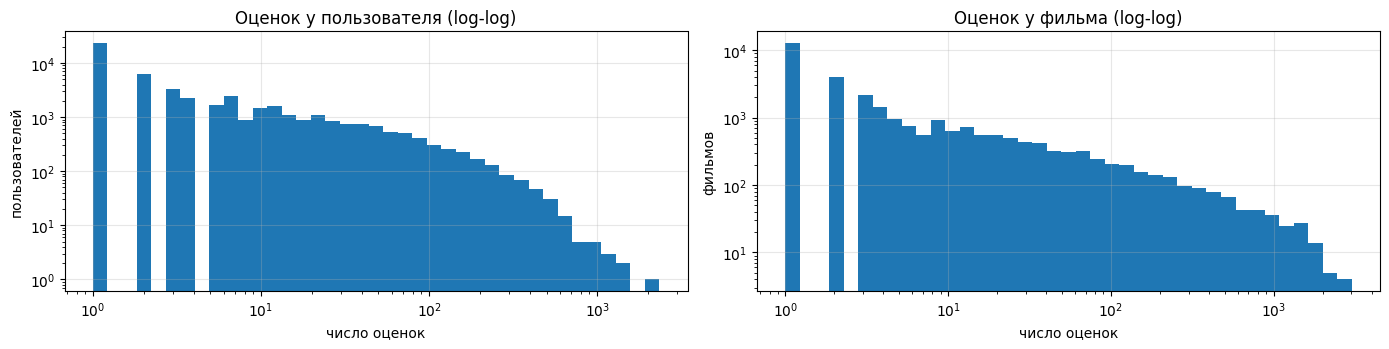

In [7]:
uc, ic = df.user_id.value_counts(), df.item_id.value_counts()
desc = pd.DataFrame({"оценок на пользователя": uc.describe(percentiles=[.25, .5, .75, .9, .99]),
                     "оценок на фильм": ic.describe(percentiles=[.25, .5, .75, .9, .99])}).T
display(desc.round(1))
print(f"пользователей с одной оценкой: {(uc == 1).mean():.1%}; фильмов с одной оценкой: {(ic == 1).mean():.1%}")
print(f"на 1% самых популярных фильмов приходится {ic.iloc[:len(ic) // 100].sum() / len(df):.1%} оценок, "
      f"на 10% — {ic.iloc[:len(ic) // 10].sum() / len(df):.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
for ax, cnt, title, ylabel in [(axes[0], uc, "Оценок у пользователя", "пользователей"),
                               (axes[1], ic, "Оценок у фильма", "фильмов")]:
    ax.hist(cnt, bins=np.logspace(0, np.log10(cnt.max() + 1), 40))
    ax.set(xscale="log", yscale="log", title=title + " (log-log)", xlabel="число оценок", ylabel=ylabel)
plt.tight_layout()
plt.show()

Обе величины распределены с тяжёлым хвостом. У медианного пользователя всего 2 оценки, у самых активных — тысячи. Половина фильмов оценена 1–2 раза, а на 1% самых популярных фильмов приходится больше трети всех оценок. Отсюда два решения:
- **Каталог кандидатов** — фильмы, у которых в train не меньше 5 оценок. Для более редких фильмов не хватает статистики, чтобы оценить сходство или выучить вектор, а их размер раздувает EASE (матрица $|I|\times|I|$).
- **Пользователей не отсекаем.** Даже одна оценка — это история, по которой можно персонализировать, и это честнее k-core. Пользователи без истории считаются холоднмыи


### Метаданные: жанры, год выпуска, возраст фильма в момент оценки

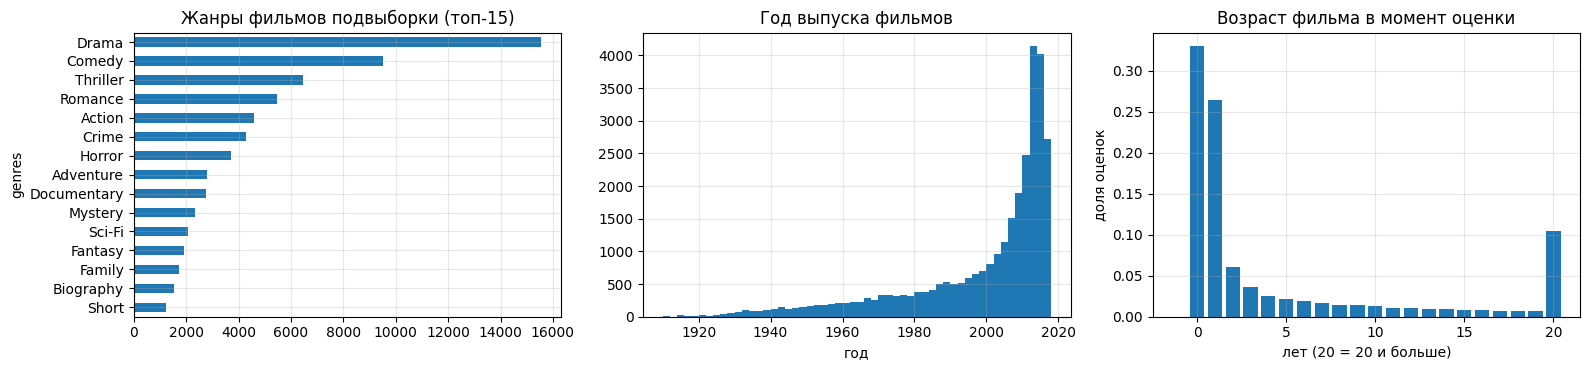

жанров: 29, в среднем 2.43 жанра на фильм; без года выпуска: 0
доля оценок фильмам, которым в момент оценки не больше 1 года: 59.4%
пересечение топ-20 фильмов соседних месяцев (Жаккар): в среднем 0.32


g,Drama,Thriller,Action,Comedy,Adventure,Sci-Fi,Crime,Romance,Fantasy,Mystery
оценок,366886.00,235441.00,217740.00,179540.00,174100.00,137320.00,133471.00,96848.00,83646.00,81504.00
средняя оценка,7.52,7.14,7.13,7.12,7.33,7.29,7.28,7.31,7.23,7.25


In [8]:
meta = movies.set_index("item_id")
m_sub = meta.loc[df.item_id.unique()]
genres = m_sub.genres.str.split("|").explode()
genres_per_movie = m_sub.genres.str.split("|").str.len().mean()
movie_age = df.dt.dt.year.to_numpy() - meta.year.reindex(df.item_id).to_numpy()   # календарных лет

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
genres.value_counts().head(15).iloc[::-1].plot.barh(ax=axes[0], title="Жанры фильмов подвыборки (топ-15)")
axes[1].hist(m_sub.year.dropna(), bins=np.arange(1910, 2020, 2))
axes[1].set(title="Год выпуска фильмов", xlabel="год")
age_share = pd.Series(np.clip(movie_age, -1, 20)).value_counts(normalize=True).sort_index()
axes[2].bar(age_share.index, age_share.values)
axes[2].set(title="Возраст фильма в момент оценки", xlabel="лет (20 = 20 и больше)", ylabel="доля оценок")
plt.tight_layout()
plt.show()

print(f"жанров: {genres.nunique()}, в среднем {genres_per_movie:.2f} жанра на фильм; без года выпуска: {m_sub.year.isna().sum()}")
print(f"доля оценок фильмам, которым в момент оценки не больше 1 года: {(movie_age <= 1).mean():.1%}")
tops = df.groupby(df.dt.dt.to_period("M")).item_id.agg(lambda s: set(s.value_counts().index[:20]))
jaccard = [len(a & b) / len(a | b) for a, b in zip(tops.iloc[:-1], tops.iloc[1:])]
print(f"пересечение топ-20 фильмов соседних месяцев (Жаккар): в среднем {np.mean(jaccard):.2f}")
by_genre = df.assign(g=df.item_id.map(meta.genres).str.split("|")).explode("g").groupby("g").rating
genre_stats = by_genre.agg(["size", "mean"]).rename(columns={"size": "оценок", "mean": "средняя оценка"})
display(genre_stats.sort_values("оценок", ascending=False).head(10).round(2).T)

Метаданные пригодны для FM. Жанры (29 значений вместе с `Unknown`, в среднем 2,4 на фильм) описывают содержание, год выпуска — эпоху. Средняя оценка по жанрам различается слабо (7,1–7,5), так что жанр говорит скорее о том, *что* человек смотрит, чем о том, как он оценивает.

Главная особенность данных — **новизна**. Около 60% оценок ставятся фильмам, которым в этот момент не больше года. Топ-20 популярных фильмов соседних месяцев пересекается всего примерно на треть. Пользователи в основном оценивают то, что сейчас в прокате, поэтому популярность «за всё время» почти ничего не говорит о следующих месяцах.

Из этого следуют три решения:
1. Разбиение должно быть строго временным.
2. В FM добавляем признаки момента времени: возраст фильма и его недавнюю популярность.
3. Целевой сигнал пятой модели строим с учётом давности взаимодействия.

## 3. Протокол оценки

**Глобальное временное разбиение** (все модели видят одно и то же):

| Этап | Обучение (train) | Окно оценки | Назначение |
|---|---|---|---|
| validation-1 | 28.02.2013 – 30.06.2016 | 01.07.2016 – 31.12.2016 | подбор гиперпараметров |
| validation-2 | 28.02.2013 – 31.12.2016 | 01.01.2017 – 30.06.2017 | подбор гиперпараметров |
| test | 28.02.2013 – 30.06.2017 | 01.07.2017 – 31.12.2017 | финальное сравнение, один прогон |

Рекомендации строятся один раз, в момент $t_{rec}$ (начало окна), и проверяются на всём следующем полугодии. После подбора каждая модель переобучается на всех данных до 01.07.2017 с выбранными настройками и один раз оценивается на test.

**Почему два окна валидации.** В данных сильная сезонность. Зимой досматривают декабрьские премьеры и фильмы оскаровского сезона, летом выходят свои блокбастеры. Настройка, лучшая на одном полугодии, может выиграть за счёт особенностей именно этого сезона. Например, стратегия «рекомендуй самые свежие фильмы» в январе попадает в рождественские премьеры, а в июле — нет. Поэтому гиперпараметры выбираются по **среднему** NDCG@10 на двух соседних полугодиях с разной сезонностью: лето–осень 2016 и зима–весна 2017. Test в подборе не участвует.

**Кандидаты.** Каталог этапа — фильмы, у которых в train этапа не меньше `MIN_ITEM_TRAIN = 5` оценок. Статистика считается только по прошлому. Кандидаты пользователя — весь каталог, кроме фильмов, которые он уже оценил в train. Каталог и правило исключения одинаковы для всех моделей.

**Новые пользователи и фильмы.**
- Пользователь без истории в train — холодный. Его не оцениваем так как персонализировать нечем, в продакшене ему показали бы популярное.
- Фильм вне каталога (вышел после $t_{rec}$ или набрал меньше 5 оценок) не может рекомендовать ни одна модель, поэтому он исключается из релевантных.

Доли потерянных так релевантных взаимодействий приведены в таблице ниже.

**Релевантность и пользователи оценки.** Релевантны фильмы каталога, которые пользователь оценил в окне на 7 и выше. Метрики считаются по тёплым пользователям, у которых в окне есть хотя бы один такой фильм. Уже оценённые фильмы исключены из выдачи, а повторных оценок одного фильма в данных нет, так что релевантный фильм всегда находится среди кандидатов.

**Метрики при K = 10.** Обе метрики усредняются по пользователям; основная выбрана до подбора.
- **NDCG@10 — основная.** Пользователь видит упорядоченный список, и важно, насколько высоко в нём стоят фильмы, которые ему понравятся. $\mathrm{NDCG@10}_u=\frac{1}{\mathrm{IDCG}_u}\sum_{j=1}^{10}\frac{[T_{uj}\in G_u]}{\log_2(j+1)}$, где $\mathrm{IDCG}_u=\sum_{j=1}^{\min(10,|G_u|)}\frac{1}{\log_2(j+1)}$.
- **Recall@10.** Доля будущих понравившихся фильмов, которые попали в десятку, то есть насколько полно рекомендации покрывают то, что пользователь посмотрит: $\mathrm{Recall@10}_u=|T_u\cap G_u|/|G_u|$.
- **Coverage@10** (вспомогательная). Доля каталога, которая попала хотя бы в одну выдачу, $|I_P|/|I|$. Показывает, не сводится ли модель к рекомендации одних и тех же хитов.

Здесь $T_u$ — top-10 модели, $G_u$ — релевантные фильмы пользователя в окне.

In [9]:
t_val1, t_val2, t_test, t_end = (int(t.timestamp()) for t in (T_VAL1, T_VAL2, T_TEST, DATA_END))
val1 = make_stage(df, t_val1, t_val2, "validation-1", MIN_ITEM_TRAIN, REL_THRESHOLD)
val2 = make_stage(df, t_val2, t_test, "validation-2", MIN_ITEM_TRAIN, REL_THRESHOLD)
test = make_stage(df, t_test, t_end, "test", MIN_ITEM_TRAIN, REL_THRESHOLD)
VAL_FOLDS = [val1, val2]

stage_table = pd.DataFrame({s.name: {k: (f"{v:.1%}" if k.startswith("share") else f"{v:,}")
                                      for k, v in s.stats.items()} for s in (val1, val2, test)})
stage_table.index = ["взаимодействий в train", "пользователей в train", "фильмов в каталоге",
                     "взаимодействий в окне", "из них релевантных (оценка >= 7)",
                     "доля релевантных: холодный пользователь", "доля релевантных: фильм вне каталога",
                     "пользователей в оценке", "релевантных пар (u, i) в оценке"]
display(stage_table)

,validation-1,validation-2,test
взаимодействий в train,"480,602","533,658","587,663"
пользователей в train,"41,957","45,271","48,256"
фильмов в каталоге,"7,891","8,496","9,022"
взаимодействий в окне,"54,705","55,879","50,058"
из них релевантных (оценка >= 7),"39,362","41,122","35,732"
доля релевантных: холодный пользователь,21.4%,19.9%,17.6%
доля релевантных: фильм вне каталога,38.5%,28.9%,37.6%
пользователей в оценке,"3,499","4,091","3,630"
"релевантных пар (u, i) в оценке","18,995","23,382","18,136"


От 29% до 38% релевантных оценок окна приходятся на фильмы вне каталога, в основном на новинки, вышедшие уже после $t_{rec}$. Это прямое следствие новизны (раздел 2.4) и общее ограничение для всех моделей. Ещё 18–21% приходятся на холодных пользователей. В каждом окне остаётся 3,5–4,1 тыс. пользователей и 18–23 тыс. релевантных пар; этого хватает для устойчивого сравнения, доверительные интервалы считаем в разделе 5.

**Ориентиры.** Это не одна из пяти моделей, а точки отсчёта, без которых не понять масштаб метрик: популярное за всё время и популярное за последние 30 дней перед $t_{rec}$.

In [10]:
baseline_rows = []
for fold in VAL_FOLDS:
    for model in (Popular(), Popular(days=30)):
        baseline_rows.append({"окно": fold.name, "модель": model.name, **evaluate(model.fit(fold), fold)})
display(pd.DataFrame(baseline_rows).set_index(["окно", "модель"]).round(4))

NDCG@10  Recall@10  Coverage@10
окно         модель                                      
validation-1 Popular       0.0088     0.0114       0.0087
             Popular-30d   0.0879     0.1305       0.0035
validation-2 Popular       0.0058     0.0068       0.0080
             Popular-30d   0.1252     0.1866       0.0040

Популярное за всё время почти бесполезно: прошлые хиты пользователи уже посмотрели, и они исключены из выдачи. Популярное за последний месяц на порядок сильнее. Это количественно подтверждает, что будущие просмотры определяются тем, что актуально сейчас. Уровень метрик заметно зависит от окна: зимой–весной 2017 те же правила дают NDCG@10 выше, чем летом–осенью 2016. Это ещё одно проявление сезонности.

## 4. Модели и подбор гиперпараметров

Каждая конфигурация обучается на train обоих окон валидации, а выбирается по **среднему** NDCG@10 по двум окнам; в таблицах есть и значения по каждому окну. Для итеративных моделей (iALS, FM) число итераций или эпох тоже гиперпараметр: метрики снимаются в контрольных точках одного запуска. Для ItemKNN и EASE перебирается полная сетка, для iALS, FM и модели 5 — случайный поиск по сетке с фиксированным зерном.

In [11]:
def sample_configs(space: dict, n: int, seed: int = SEED) -> list:
    # n разных конфигураций, выбранных равномерно из декартова произведения сетки
    rng = np.random.default_rng(seed)
    configs = []
    while len(configs) < n:
        cfg = {k: v[rng.integers(len(v))] for k, v in space.items()}
        if cfg not in configs:
            configs.append(cfg)
    return configs


def tune(make_model, configs, checkpoints=None, iter_name="iterations"):
    # make_model(cfg, n_iter) -> модель. Каждая конфигурация обучается на обоих окнах валидации;
    # метрики усредняются по окнам. В столбце _cfg — точная конфигурация (вместе с числом итераций/эпох)
    rows = []
    for cfg in configs:
        t0 = time.perf_counter()
        per_fold = []
        for fold in VAL_FOLDS:
            res = {}
            if checkpoints is None:
                res[None] = evaluate(make_model(cfg, None).fit(fold), fold)
            else:
                def callback(model, it, fold=fold, res=res):
                    if it in checkpoints:
                        res[it] = evaluate(model, fold)
                make_model(cfg, max(checkpoints)).fit(fold, callback=callback)
            per_fold.append(res)
        for it in per_fold[0]:
            row = {"_cfg": dict(cfg) if it is None else {**cfg, iter_name: it}, **cfg}
            if it is not None:
                row[iter_name] = it
            for metric in per_fold[0][it]:
                row[metric] = float(np.mean([res[it][metric] for res in per_fold]))
            for j, res in enumerate(per_fold, 1):
                row[f"{PRIMARY} окно {j}"] = res[it][PRIMARY]
            row["время, с"] = time.perf_counter() - t0
            rows.append(row)
    return pd.DataFrame(rows).sort_values(PRIMARY, ascending=False).reset_index(drop=True)


def best_params(table):
    return dict(table.iloc[0]["_cfg"])


def show(table, n=8):
    display(table.drop(columns="_cfg").head(n).round(4))


search, best = {}, {}

### Item-based kNN

**Постановка.** Пользователю нравятся фильмы, похожие на те, что он уже смотрел; сходство фильмов определяется по пересечению их аудиторий. Матрица $X\in\{0,1\}^{|U|\times|I|}$ хранит факт оценки (неявная обратная связь, значение оценки не используется).

**Сходство** — косинус со сжатием, который штрафует пары с маленькой общей аудиторией:
$$s_{ij}=\frac{\langle x_i,x_j\rangle}{\|x_i\|\,\|x_j\|+h},\qquad s_{ii}=0,$$
где $x_i$ — столбец $X$, то есть множество зрителей фильма $i$.

**Рекомендации.** Для кандидата $i$ берём его $k$ ближайших соседей $N_k(i)$ и суммируем сходства с фильмами из истории пользователя:
$$\hat r_{ui}=\sum_{j\in I(u)\cap N_k(i)} s_{ij}.$$
Затем выбираем top-10 непросмотренных. Item-based вариант выбран потому, что фильмов в каталоге примерно в 5 раз меньше, чем пользователей, а у фильма каталога не меньше 5 оценок. Сходства фильмов поэтому надёжнее, чем сходства пользователей, у которых медиана — 2 оценки.

**Пространство поиска** (полная сетка, 24 точки): $k\in\{10, 20, 50, 100, 200, 500\}$, $h\in\{0, 10, 50, 200\}$.

,k,shrink,NDCG@10,Recall@10,Coverage@10,NDCG@10 окно 1,NDCG@10 окно 2,"время, с"
0,50,0,0.0246,0.0292,0.2733,0.0265,0.0226,10.4629
1,50,10,0.0244,0.0296,0.2459,0.0265,0.0224,11.2299
2,10,10,0.0243,0.0303,0.2682,0.0266,0.0219,9.9549
3,50,50,0.0240,0.0286,0.2188,0.0266,0.0214,11.7114
4,10,50,0.0238,0.0293,0.2665,0.0257,0.0219,10.7204


лучшие параметры: {'k': 50, 'shrink': 0}


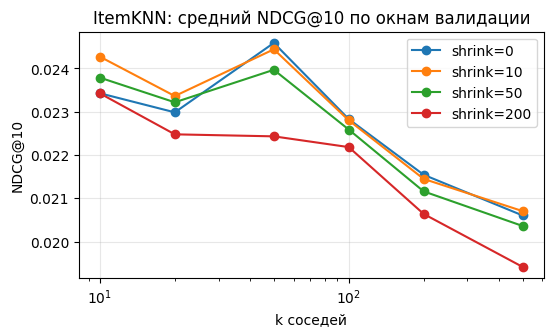

In [12]:
knn_space = {"k": [10, 20, 50, 100, 200, 500], "shrink": [0, 10, 50, 200]}
knn_configs = [{"k": k, "shrink": h} for k in knn_space["k"] for h in knn_space["shrink"]]
search["ItemKNN"] = tune(lambda cfg, _: ItemKNN(**cfg), knn_configs)
best["ItemKNN"] = best_params(search["ItemKNN"])
show(search["ItemKNN"], 5)
print("лучшие параметры:", best["ItemKNN"])
pivot = search["ItemKNN"].pivot(index="k", columns="shrink", values=PRIMARY)
fig, ax = plt.subplots(figsize=(6, 3.2))
for h in pivot.columns:
    ax.plot(pivot.index, pivot[h], marker="o", label=f"shrink={h}")
ax.set(xscale="log", xlabel="k соседей", ylabel=PRIMARY, title="ItemKNN: средний NDCG@10 по окнам валидации")
ax.legend()
plt.show()

### iALS

**Почему неявный вариант.** Задача — top-N, а не предсказание оценки. Для ранжирования важно, что пользователь *выбрал* фильм, а явный ALS обучается только на наблюдаемых оценках и ничего не знает о том, чего пользователь не смотрел. iALS лучше подходит для генерации кандидатов.

**Постановка**:
$$p_{ui}=\begin{cases}1,& (u,i)\text{ наблюдалась}\\0,&\text{иначе}\end{cases},\qquad c_{ui}=1+\alpha\,[(u,i)\text{ наблюдалась}],$$
$$\min_{X,Y}\sum_{u,i}c_{ui}\,(p_{ui}-x_u^\top y_i)^2+\lambda\Big(\sum_u C_u\|x_u\|^2+\sum_i C_i\|y_i\|^2\Big),\qquad C_u=\frac{(\sum_i c_{ui})^{\nu}\,|U|}{\sum_v(\sum_i c_{vi})^{\nu}}.$$
Сумма идёт по **всем** парам. При $\nu=0$ регуляризация обычная; при $\nu>0$ активные пользователи и популярные фильмы регуляризуются сильнее.

**Шаг ALS.** При фиксированном $Y$ задача распадается на независимые ridge-регрессии по пользователям:
$$x_u=\big(Y^\top Y+\lambda C_u I+Y^\top(C^u-I)Y\big)^{-1}\,Y^\top C^u p_u.$$
$Y^\top Y$ считается один раз на шаг, а поправка $Y^\top(C^u-I)Y$ затрагивает только просмотренные фильмы. Шаг по $Y$ симметричен. Системы решаются методом сопряжённых градиентов: 3 шага с тёплым стартом от предыдущей итерации. Произведение $A_u z$ считается векторно сразу для всех пользователей без построения матриц $k\times k$.

**Рекомендации:** $\hat r_{ui}=x_u^\top y_i$, top-10 среди непросмотренных.

**Пространство поиска** (случайный поиск, 12 конфигураций; итерации 5/10/15 в одном запуске): факторы $\{32, 64\}$, $\lambda\in\{1, 3, 10, 30, 100, 300, 1000\}$, $\alpha\in\{1, 3, 10, 30, 100\}$, $\nu\in\{0, 0.5, 1\}$.

In [13]:
als_space = {"factors": [32, 64], "reg": [1.0, 3.0, 10.0, 30.0, 100.0, 300.0, 1000.0],
             "alpha": [1.0, 3.0, 10.0, 30.0, 100.0], "reg_exponent": [0.0, 0.5, 1.0]}
ALS_CHECKPOINTS = (5, 10, 15)
search["iALS"] = tune(lambda cfg, n: IALS(**cfg, iterations=n, seed=SEED),
                      sample_configs(als_space, 12, seed=SEED), checkpoints=ALS_CHECKPOINTS)
best["iALS"] = best_params(search["iALS"])
show(search["iALS"])
print("лучшие параметры:", best["iALS"])

,factors,reg,alpha,reg_exponent,iterations,NDCG@10,Recall@10,Coverage@10,NDCG@10 окно 1,NDCG@10 окно 2,"время, с"
0,64,300.0,30.0,1.0,15,0.0274,0.0352,0.0952,0.0275,0.0273,120.1532
1,64,10.0,1.0,1.0,15,0.0270,0.0332,0.0822,0.0280,0.0261,119.8852
2,64,100.0,10.0,1.0,15,0.0269,0.0346,0.1016,0.0284,0.0254,112.9521
3,64,10.0,1.0,1.0,10,0.0269,0.0328,0.0739,0.0283,0.0254,119.8851
4,64,300.0,30.0,1.0,10,0.0267,0.0337,0.0881,0.0265,0.0270,120.1531
5,64,10.0,1.0,1.0,5,0.0266,0.0323,0.0597,0.0278,0.0255,119.8850
6,64,100.0,10.0,1.0,10,0.0265,0.0338,0.0945,0.0281,0.0249,112.9519
7,64,300.0,30.0,0.0,15,0.0261,0.0328,0.0987,0.0285,0.0237,114.3097


лучшие параметры: {'factors': 64, 'reg': 300.0, 'alpha': 30.0, 'reg_exponent': 1.0, 'iterations': 15}


### EASE

**Постановка** Это линейная модель «фильм → фильм», которая восстанавливает строку взаимодействий пользователя через его же остальные фильмы:
$$\min_B\ \|X-XB\|_F^2+\lambda\|B\|_F^2\quad\text{s.t.}\ \operatorname{diag}(B)=0.$$
Ограничение на диагональ запрещает тривиальное решение $B=I$. В отличие от SLIM здесь нет $L_1$-штрафа и ограничения $B\ge0$, поэтому решение выписывается в замкнутом виде:
$$P=(X^\top X+\lambda I)^{-1},\qquad B_{ij}=-\frac{P_{ij}}{P_{jj}}\ (i\ne j),\quad B_{jj}=0.$$
Обращаем через разложение Холецкого: матрица $X^\top X+\lambda I$ симметрична и положительно определена.

**Рекомендации:** $\hat r_u=x_uB$, top-10 среди непросмотренных.

**Пространство поиска** (полная сетка): $\lambda\in\{10, 30, 100, 300, 1000\}$.

In [14]:
ease_space = {"lam": [10.0, 30.0, 100.0, 300.0, 1000.0]}
search["EASE"] = tune(lambda cfg, _: EASE(**cfg), [{"lam": l} for l in ease_space["lam"]])
best["EASE"] = best_params(search["EASE"])
show(search["EASE"].sort_values("lam"))
print("лучшие параметры:", best["EASE"])

,lam,NDCG@10,Recall@10,Coverage@10,NDCG@10 окно 1,NDCG@10 окно 2,"время, с"
4,10.0,0.0245,0.0297,0.1597,0.0247,0.0244,40.5210
3,30.0,0.0259,0.0316,0.1461,0.0267,0.0251,39.7525
1,100.0,0.0263,0.0318,0.1388,0.0276,0.0251,39.2421
0,300.0,0.0266,0.0325,0.1308,0.0282,0.0250,38.9415
2,1000.0,0.0262,0.0320,0.1212,0.0291,0.0232,39.3147


лучшие параметры: {'lam': 300.0}


### Factorization Machine с метапризнаками

**Модель** линейная модель с попарными взаимодействиями признаков через латентные векторы:
$$a(x)=w_0+\sum_f w_fx_f+\sum_{f<g}\langle v_f,v_g\rangle x_fx_g=w_0+\sum_f w_fx_f+\tfrac12\Big(\big\|\textstyle\sum_f v_fx_f\big\|^2-\sum_f\|v_f\|^2x_f^2\Big).$$
Второй вид считается за $O(kn_x)$, где $n_x$ — число ненулевых признаков.

**Признаки.** Вектор $x(u,i,t)$ описывает пару «пользователь — фильм» в момент $t$. Все признаки доступны в момент рекомендации: метаданные фильма известны заранее, а контекст считается только по оценкам **строго до** $t$. При рекомендации $t=t_{rec}$.

| Группа | Признаки | Зачем |
|---|---|---|
| пользователь | one-hot `user_id` | вектор вкуса пользователя |
| фильм | one-hot `item_id` (включение — гиперпараметр) | коллаборативная часть |
| метаданные фильма | жанры (multi-hot с весом $1/n_i$, $n_i$ — число жанров фильма); эпоха выпуска (10 корзин) | вкус к жанрам и эпохам, обобщение на фильмы с малым числом оценок |
| контекст момента $t$ | возраст фильма $\lfloor t\rfloor_{год}-\text{год выпуска}$ (8 корзин); число оценок фильма за 30 дней до $t$ (10 лог-корзин); $\log(1+n_{7д})$ и $\log(1+n_{30д})$ как числа | раздел 2.4: смотрят новинки и то, что популярно сейчас |

**Обучение.** Лосс BPR для ранжирования:
$$\mathcal L=-\sum_{(u,i,t)}\ln\sigma\big(a(x(u,i,t))-a(x(u,j,t))\big)+\lambda\|\Theta\|^2.$$
Здесь $(u,i,t)$ — оценка из train, а $j$ — случайный фильм каталога, который пользователь не оценивал. Контекст негатива берётся в тот же момент $t$, поэтому модель учится отличать то, что выбрали в момент $t$, от остального каталога в тот же момент. Слагаемые, зависящие только от пользователя, в разности сокращаются.

Оптимизатор — Adagrad по батчам из 4096 троек. Градиенты выписаны вручну. Рекомендации строятся по экспоненциальному среднему параметров (EMA, 0.99 на батч): без него метрика заметно скачет от эпохи к эпохе.

**Рекомендации:** $\hat r_{ui}=a(x(u,i,t_{rec}))$, top-10 среди непросмотренных.

**Пространство поиска** (случайный поиск, 8 конфигураций; эпохи 1–8 в одном запуске): факторы $\{16, 32, 64, 128\}$, шаг $\{0.02, 0.05, 0.1\}$, $\lambda\in\{10^{-4}, 10^{-3}, 10^{-2}\}$, `item_id` $\in\{\text{да}, \text{нет}\}$.

In [15]:
fm_space = {"factors": [16, 32, 64, 128], "lr": [0.02, 0.05, 0.1], "reg": [1e-4, 1e-3, 1e-2],
            "use_item_id": [True, False]}
FM_EPOCHS = tuple(range(1, 9))
search["FM"] = tune(lambda cfg, n: FactorizationMachine(movies, **cfg, epochs=n, seed=SEED),
                    sample_configs(fm_space, 8, seed=SEED), checkpoints=FM_EPOCHS, iter_name="epochs")
best["FM"] = best_params(search["FM"])
show(search["FM"])
print("лучшие параметры:", best["FM"])

,factors,lr,reg,use_item_id,epochs,NDCG@10,Recall@10,Coverage@10,NDCG@10 окно 1,NDCG@10 окно 2,"время, с"
0,64,0.05,0.0010,True,2,0.1223,0.1492,0.0140,0.0775,0.1671,340.5233
1,64,0.05,0.0010,True,3,0.1130,0.1434,0.0199,0.0789,0.1470,340.5233
2,64,0.05,0.0010,True,1,0.1122,0.1585,0.0066,0.0864,0.1381,340.5232
3,128,0.05,0.0010,False,8,0.1102,0.1582,0.0358,0.0923,0.1281,361.7193
4,128,0.05,0.0010,False,7,0.1093,0.1577,0.0313,0.0918,0.1269,361.7192
5,128,0.05,0.0010,False,5,0.1084,0.1564,0.0232,0.0914,0.1254,361.7190
6,128,0.05,0.0010,False,6,0.1081,0.1558,0.0276,0.0904,0.1257,361.7191
7,32,0.10,0.0001,False,6,0.1077,0.1539,0.0332,0.0864,0.1291,186.4761


лучшие параметры: {'factors': 64, 'lr': 0.05, 'reg': 0.001, 'use_item_id': True, 'epochs': 2}


### iALS с собственным целевым сигналом

**Почему этот вариант пятой модели.** Задача — top-N по неявному выбору. timeSVD++ оптимизирует RMSE на наблюдаемых оценках и не учится тому, что пользователь вообще выберет, а временную динамику можно встроить прямо в таргет iALS.

**Идея.** Базовый iALS учит таргет $p_{ui}=1$ — «пользователь когда-то посмотрел фильм». Мы же хотим предсказать другое: **понравится ли фильм пользователю в ближайшие месяцы**. Базовый таргет расходится с этим в двух местах, и EDA показывает, что оба расхождения существенны:
1. **Оценка.** Фильм с оценкой 2 и фильм с оценкой 10 для базового таргета одинаковые положительные примеры. При этом 28% просмотров заканчиваются оценкой ниже 7, то есть по нашему критерию это неудачи.
2. **Время.** Просмотр четырёхлетней давности весит столько же, сколько вчерашний. Но выбор определяется новизной: 60% оценок ставятся фильмам не старше года, а топ-20 обновляется на две трети за месяц. Поэтому популярное за 30 дней в 10–20 раз сильнее популярного за всё время.

**Таргет — «актуальное удовольствие»:**
$$\boxed{\,p_{ui}=s(r_{ui})\cdot d(t_{rec}-t_{ui}),\qquad s(r)=\Big(\frac{r-1}{9}\Big)^{\gamma},\qquad d(\Delta)=2^{-\Delta/h}\,}$$
- $s(r)\in[0,1]$ — насколько фильм понравился: $s(10)=1$, $s(1)=0$, а при $\gamma=1$ оценка 7 даёт $s=0{,}67$. Параметр $\gamma$ управляет тем, насколько резко отделяются любимые фильмы. Оценка 1–2 даёт таргет около 0 при уверенности $1+\alpha$. Значит, модель уверенно учит такое не предлагать
- $d(\Delta)\in(0,1]$ — насколько интерес ещё актуален к моменту рекомендации. $h$ — период полураспада в днях.
- Для ненаблюдаемых пар по-прежнему $p_{ui}=0,\ c_{ui}=1$. Уверенность для наблюдаемых пар **не меняется**: $c_{ui}=1+\alpha$, как в модели 2. Значит, разница с базовой моделью — именно в том, *что* модель учится предсказывать, а не в весах.
- Базовый iALS — частный случай: $\gamma=0,\ h=\infty$ даёт $p_{ui}=1$.

Всё вычисляется по train этапа и по моменту $t_{rec}$, то есть доступно в момент рекомендации. Критерий релевантности на test тот же, что у остальных моделей.

**Пространство поиска** — совместный случайный поиск, 20 конфигураций: пространство iALS из 4.2 плюс $\gamma\in\{0, 1, 2\}$ и $h\in\{30, 90, 180, \infty\}$ дней; итерации 5/10/15. Конфигураций больше, чем у модели 2, потому что добавились два гиперпараметра таргета. Чтобы проверить, что выигрыш даёт именно таргет, а не более удачный перебор, в разделе 5 модель 5 сравнивается с вариантом, где при её же гиперпараметрах таргет возвращён к $p=1$. Там же оценён вклад каждой компоненты таргета.

In [16]:
target_space = {"gamma": [0.0, 1.0, 2.0], "half_life": [30.0, 90.0, 180.0, None]}
custom_space = {**als_space, **target_space}
search["iALS-custom"] = tune(lambda cfg, n: IALSCustomTarget(**cfg, iterations=n, seed=SEED),
                             sample_configs(custom_space, 20, seed=SEED), checkpoints=ALS_CHECKPOINTS)
best["iALS-custom"] = best_params(search["iALS-custom"])
show(search["iALS-custom"])
print("лучшие параметры:", best["iALS-custom"])

,factors,reg,alpha,reg_exponent,gamma,half_life,iterations,NDCG@10,Recall@10,Coverage@10,NDCG@10 окно 1,NDCG@10 окно 2,"время, с"
0,64,10.0,1.0,0.5,2.0,30.0,15,0.1473,0.2059,0.0045,0.1105,0.1841,117.4630
1,64,10.0,1.0,0.5,2.0,30.0,10,0.1443,0.1996,0.0050,0.1082,0.1805,117.4629
2,64,10.0,1.0,0.5,2.0,30.0,5,0.1443,0.1997,0.0063,0.1081,0.1804,117.4628
3,32,300.0,100.0,0.5,2.0,90.0,10,0.1415,0.1846,0.0057,0.0938,0.1893,72.1965
4,32,300.0,100.0,0.5,2.0,90.0,15,0.1415,0.1846,0.0056,0.0938,0.1892,72.1968
5,32,300.0,100.0,0.5,2.0,90.0,5,0.1415,0.1845,0.0064,0.0937,0.1892,72.1963
6,32,100.0,30.0,0.0,2.0,30.0,5,0.1107,0.1473,0.0057,0.0956,0.1259,73.2099
7,64,30.0,1.0,0.0,0.0,30.0,5,0.1102,0.1609,0.0043,0.0848,0.1356,126.8713


лучшие параметры: {'factors': 64, 'reg': 10.0, 'alpha': 1.0, 'reg_exponent': 0.5, 'gamma': 2.0, 'half_life': 30.0, 'iterations': 15}


## 5. Финальное сравнение на test

Каждая модель переобучается на train + validation (данные до 01.07.2017) с выбранными гиперпараметрами, включая число итераций или эпох, и один раз оценивается на test-окне 01.07–31.12.2017. Пользователи, кандидаты и критерий релевантности у всех моделей общие. В столбцах «95% ДИ» — доверительный интервал среднего по пользователям (бутстрэп по пользователям, 2000 повторов).

In [17]:
def make_final(name):
    p = dict(best[name])
    if name == "ItemKNN":
        return ItemKNN(**p)
    if name == "iALS":
        return IALS(**p, seed=SEED)
    if name == "EASE":
        return EASE(**p)
    if name == "FM":
        return FactorizationMachine(movies, **p, seed=SEED)
    if name == "iALS-custom":
        return IALSCustomTarget(**p, seed=SEED)
    raise KeyError(name)


def test_row(name, model, params=""):
    t0 = time.perf_counter()
    model.fit(test)
    fit_s = time.perf_counter() - t0
    metrics, recs = evaluate(model, test, k=K, return_recs=True)
    per_user = per_user_metrics(recs, test.relevant)
    lo, hi = bootstrap_ci(per_user[PRIMARY], seed=SEED)
    rlo, rhi = bootstrap_ci(per_user[f"Recall@{K}"], seed=SEED)
    row = {"модель": name, PRIMARY: metrics[PRIMARY], "NDCG 95% ДИ": f"[{lo:.4f}, {hi:.4f}]",
           f"Recall@{K}": metrics[f"Recall@{K}"], "Recall 95% ДИ": f"[{rlo:.4f}, {rhi:.4f}]",
           f"Coverage@{K}": metrics[f"Coverage@{K}"], "обучение, с": round(fit_s, 1), "гиперпараметры": params}
    return row, per_user


final_rows, final_per_user = [], {}
for base in (Popular(), Popular(days=30)):
    row, pu = test_row(base.name + " (ориентир)", base)
    final_rows.append(row); final_per_user[base.name] = pu
for name in ["ItemKNN", "iALS", "EASE", "FM", "iALS-custom"]:
    row, pu = test_row(name, make_final(name), ", ".join(f"{k}={v}" for k, v in best[name].items()))
    final_rows.append(row); final_per_user[name] = pu
results = pd.DataFrame(final_rows).set_index("модель")
display(results.round(4))

,NDCG@10,NDCG 95% ДИ,Recall@10,Recall 95% ДИ,Coverage@10,"обучение, с",гиперпараметры
модель,,,,,,,
Popular (ориентир),0.0066,"[0.0053, 0.0079]",0.0077,"[0.0060, 0.0097]",0.0076,0.0,
Popular-30d (ориентир),0.0855,"[0.0796, 0.0916]",0.1040,"[0.0962, 0.1118]",0.0035,0.1,
ItemKNN,0.0219,"[0.0194, 0.0245]",0.0281,"[0.0245, 0.0322]",0.2325,4.9,"k=50, shrink=0"
iALS,0.0218,"[0.0193, 0.0246]",0.0284,"[0.0245, 0.0326]",0.0891,68.5,"factors=64, reg=300.0, alpha=30.0, reg_exponent=1.0, iterations=15"
EASE,0.0253,"[0.0226, 0.0281]",0.0324,"[0.0283, 0.0366]",0.1228,23.7,lam=300.0
FM,0.0626,"[0.0584, 0.0669]",0.0982,"[0.0908, 0.1055]",0.0125,51.7,"factors=64, lr=0.05, reg=0.001, use_item_id=True, epochs=2"
iALS-custom,0.1485,"[0.1401, 0.1566]",0.1671,"[0.1570, 0.1768]",0.0041,65.6,"factors=64, reg=10.0, alpha=1.0, reg_exponent=0.5, gamma=2.0, half_life=30.0, iterations=15"


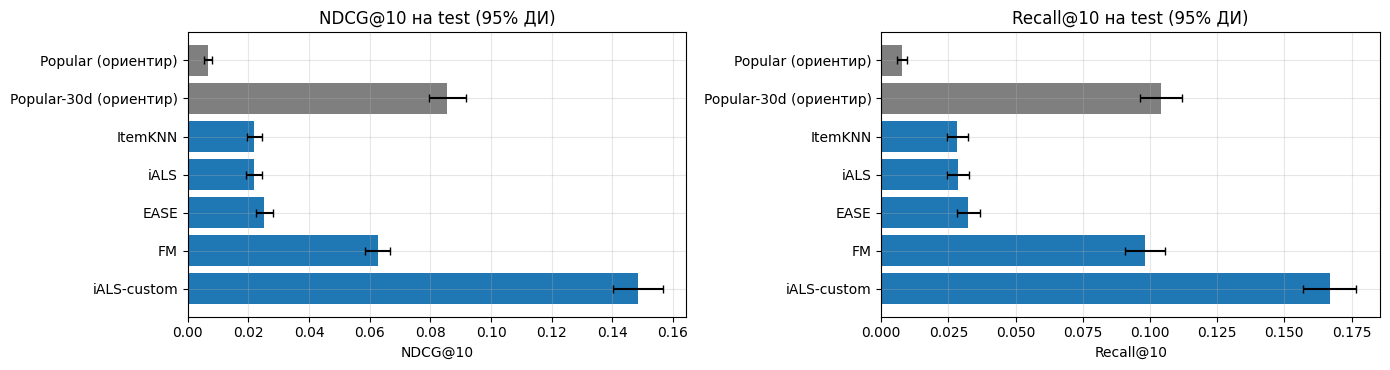

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
names = list(results.index)
colors = ["tab:gray"] * 2 + ["tab:blue"] * (len(names) - 2)
for ax, metric in zip(axes, [PRIMARY, f"Recall@{K}"]):
    vals = results[metric].to_numpy()
    ci = np.array([bootstrap_ci(final_per_user[n.replace(" (ориентир)", "")][metric], seed=SEED) for n in names])
    ax.barh(names[::-1], vals[::-1], xerr=np.abs(ci[::-1].T - vals[::-1]), color=colors[::-1], capsize=3)
    ax.set(title=f"{metric} на test (95% ДИ)", xlabel=metric)
plt.tight_layout()
plt.show()

### Вклад метаданных (FM) и собственного таргета (модель 5)

считаются на том же test, гиперпараметры берутся от полной модели и меняется только один компонент. Для вариантов FM число эпох заново выбрано на validation: без контекста модель сходится по-другому, и честнее дать каждому варианту его лучшую эпоху.

In [19]:
def fm_variant_epochs(flags):
    p = {k: v for k, v in best["FM"].items() if k != "epochs"}
    p.update(flags)
    table = tune(lambda cfg, n: FactorizationMachine(movies, **cfg, epochs=n, seed=SEED), [p],
                 checkpoints=FM_EPOCHS, iter_name="epochs")
    return best_params(table)


ablation_rows = []
fm_variants = {
    "FM: только user_id + item_id": {"use_item_id": True, "use_meta": False, "use_context": False},
    "FM: + метаданные фильма (жанры, эпоха)": {"use_item_id": True, "use_meta": True, "use_context": False},
    "FM: + контекст момента (полная, без item_id)": {"use_item_id": False, "use_meta": True, "use_context": True},
    "FM: + контекст момента (полная, с item_id)": {"use_item_id": True, "use_meta": True, "use_context": True},
}
for label, flags in fm_variants.items():
    p = fm_variant_epochs(flags)
    row, _ = test_row(label, FactorizationMachine(movies, **p, seed=SEED), f"epochs={p['epochs']}")
    ablation_rows.append(row)

pc = dict(best["iALS-custom"])
g_only = pc["gamma"] if pc["gamma"] > 0 else 1.0           # если в лучшем таргете gamma = 0, берём gamma = 1
h_only = pc["half_life"] if pc["half_life"] is not None else 90.0
custom_variants = {
    "iALS (модель 2): p = 1, свои гиперпараметры": None,
    "p = 1 при гиперпараметрах модели 5": {**pc, "gamma": 0.0, "half_life": None},
    f"только оценка: p = s(r), γ = {g_only:g}": {**pc, "gamma": g_only, "half_life": None},
    f"только давность: p = d(Δt), h = {h_only:g} дн.": {**pc, "gamma": 0.0, "half_life": h_only},
    "модель 5 (лучший таргет)": pc,
}
for label, p in custom_variants.items():
    if p is None:
        row = {"модель": label, **{k: results.loc["iALS", k] for k in results.columns}}
    else:
        row, _ = test_row(label, IALSCustomTarget(**p, seed=SEED), f"gamma={p['gamma']}, half_life={p['half_life']}")
    ablation_rows.append(row)
ablation = pd.DataFrame(ablation_rows).set_index("модель")
display(ablation[[PRIMARY, "NDCG 95% ДИ", f"Recall@{K}", f"Coverage@{K}", "гиперпараметры"]].round(4))

,NDCG@10,NDCG 95% ДИ,Recall@10,Coverage@10,гиперпараметры
модель,,,,,
FM: только user_id + item_id,0.0166,"[0.0145, 0.0188]",0.0207,0.0683,epochs=8
"FM: + метаданные фильма (жанры, эпоха)",0.0125,"[0.0108, 0.0144]",0.0167,0.0485,epochs=7
"FM: + контекст момента (полная, без item_id)",0.1056,"[0.0993, 0.1118]",0.1570,0.0190,epochs=8
"FM: + контекст момента (полная, с item_id)",0.0626,"[0.0584, 0.0669]",0.0982,0.0125,epochs=2
"iALS (модель 2): p = 1, свои гиперпараметры",0.0218,"[0.0193, 0.0246]",0.0284,0.0891,"factors=64, reg=300.0, alpha=30.0, reg_exponent=1.0, iterations=15"
p = 1 при гиперпараметрах модели 5,0.0267,"[0.0239, 0.0296]",0.0353,0.0661,"gamma=0.0, half_life=None"
"только оценка: p = s(r), γ = 2",0.0280,"[0.0250, 0.0309]",0.0376,0.0438,"gamma=2.0, half_life=None"
"только давность: p = d(Δt), h = 30 дн.",0.0971,"[0.0909, 0.1037]",0.1358,0.0033,"gamma=0.0, half_life=30.0"
модель 5 (лучший таргет),0.1485,"[0.1401, 0.1566]",0.1671,0.0041,"gamma=2.0, half_life=30.0"


In [20]:
summary = results[[PRIMARY, f"Recall@{K}", f"Coverage@{K}", "гиперпараметры"]].copy()
summary["NDCG@10 на validation (среднее 2 окон)"] = [np.nan, np.nan] + [search[n].iloc[0][PRIMARY] for n in summary.index[2:]]
display(summary.round(4))

,NDCG@10,Recall@10,Coverage@10,гиперпараметры,NDCG@10 на validation (среднее 2 окон)
модель,,,,,
Popular (ориентир),0.0066,0.0077,0.0076,,NaN
Popular-30d (ориентир),0.0855,0.1040,0.0035,,NaN
ItemKNN,0.0219,0.0281,0.2325,"k=50, shrink=0",0.0246
iALS,0.0218,0.0284,0.0891,"factors=64, reg=300.0, alpha=30.0, reg_exponent=1.0, iterations=15",0.0274
EASE,0.0253,0.0324,0.1228,lam=300.0,0.0266
FM,0.0626,0.0982,0.0125,"factors=64, lr=0.05, reg=0.001, use_item_id=True, epochs=2",0.1223
iALS-custom,0.1485,0.1671,0.0041,"factors=64, reg=10.0, alpha=1.0, reg_exponent=0.5, gamma=2.0, half_life=30.0, iterations=15",0.1473


## 6. Выводы

**Итог на test** (NDCG@10, в скобках 95% ДИ):

| Место | Модель | NDCG@10 | Recall@10 | Coverage@10 |
|---|---|---|---|---|
| 1 | iALS с собственным таргетом (модель 5) | **0.149** [0.140; 0.157] | 0.167 | 0.4% |
| — | ориентир: популярное за 30 дней | 0.086 [0.079; 0.092] | 0.104 | 0.4% |
| 2 | FM с метапризнаками (модель 4) | 0.063 [0.058; 0.067] | 0.098 | 1.3% |
| 3 | EASE | 0.025 [0.023; 0.028] | 0.032 | 12.3% |
| 4–5 | ItemKNN / iALS | 0.022 / 0.022 | 0.028 / 0.028 | 23.2% / 8.9% |

1. **Лучшая модель — iALS с собственным таргетом.** Она в 1,7 раза выше популярного за 30 дней и в 6,8 раза выше базового iALS при том же функционале и той же уверенности. Доверительные интервалы не пересекаются. На validation было 0.147 (среднее двух окон), на test 0.149: выбранная настройка перенеслась без потерь.
2. **Модели без учёта времени (ItemKNN, iALS, EASE) близки между собой.** Их интервалы пересекаются; EASE формально лучший. Все трое в 3–4 раза уступают популярному за 30 дней. Причина — новизна (раздел 2.4): 59% оценок ставятся фильмам не старше года, топ месяца быстро обновляется. Эти модели учатся на четырёх годах истории, где каждая оценка весит одинаково, и предлагают фильмы, похожие на прошлые просмотры пользователя. А смотреть он будет то, что актуально сейчас. ItemKNN разнообразнее всех (Coverage 23%), но угадывает реже, чем один общий список текущих хитов.

**Как повлиял собственный таргет**:

| Вариант (гиперпараметры модели 5) | NDCG@10 |
|---|---|
| $p=1$, гиперпараметры модели 2 | 0.022 |
| $p=1$ | 0.027 |
| только оценка, $s(r)$, $\gamma=2$ | 0.028 |
| только давность, $d(\Delta t)$, $h=30$ дн. | 0.097 |
| $s(r)\cdot d(\Delta t)$ — модель 5 | **0.149** |

- Одни гиперпараметры модели 5 без нового таргета почти ничего не дают (0.022 → 0.027). Значит, выигрыш создаёт сам таргет, а не перебор.
- Главная компонента — давность: ×3,6 к $p=1$.
- Оценка сама по себе почти бесполезна (+5%), но вместе с давностью добавляет ещё +53% (0.097 → 0.149). Среди свежих просмотров она отделяет понравившиеся фильмы от просто модных, а именно этого требует критерий релевантности. Все лучшие конфигурации поиска — с $\gamma=2$, то есть с сильным акцентом на высокие оценки.
- Цена — разнообразие: Coverage@10 = 0.4%, на всех пользователей около 40 фильмов. Модель по сути упорядочивает под каждого пользователя небольшой набор актуальных и хорошо оценённых фильмов.

**Как повлияли метаданные** 
| Признаки FM | NDCG@10 |
|---|---|
| user_id + item_id | 0.017 |
| + жанры и эпоха выпуска | 0.013 |
| + контекст момента (возраст фильма, популярность за 7/30 дней), без item_id | 0.106 |
| + контекст момента, с item_id — выбранная по validation | 0.063 |

- Статичные метаданные фильма top-N не улучшили. Жанр и эпоха описывают, какой это фильм, но не говорят, будут ли его смотреть в ближайшие месяцы.
- Весь выигрыш FM дают признаки момента времени: ×6 к FM только на id. Вариант без item_id превосходит и популярное за 30 дней (0.106 против 0.086, интервалы не пересекаются).
- **Выбор `item_id` по validation не перенёсся на test.** По среднему двух окон победил вариант с item_id: 0.122 против 0.110. Но выиграл он только зимнее окно (0.167 против 0.128) и проиграл летне-осеннее (0.078 против 0.092). Test — тоже лето–осень, и там вариант без item_id лучше почти вдвое. Объяснение: у новинки мало оценок, и все они сделаны в последние дни перед $t_{rec}$, поэтому вектор её id переобучается на «свежесть». Зимой свежие фильмы — рождественские блокбастеры, и это работает; летом — нет. Это та же сезонность, ради которой мы взяли два окна валидации. Двух окон оказалось недостаточно, чтобы отсечь эту настройку. По test модель мы не перевыбирали.

**Лучшие настройки.**
- ItemKNN: $k=50$, без сжатия. Небольшие окрестности лучше: при $k=500$ метрика падает примерно на 15%, сильное сжатие ($h=200$) мешает, так как подавляет сходства с новыми фильмами.
- iALS: 64 фактора, $\lambda=300$, $\alpha=30$, $\nu=1$, 15 итераций.
- EASE: $\lambda=300$, плато на 100–1000.
- FM: 64 фактора, шаг 0.05, $\lambda=10^{-3}$, 2 эпохи. С item_id качество падает уже после 2–3 эпох, без него растёт до 8-й.
- Модель 5: $\gamma=2$, $h=30$ дней, 64 фактора, $\lambda=10$, $\alpha=1$, $\nu=0.5$, 15 итераций.

**Ограничения эксперимента.**
- Схема с двумя окнами валидации появилась после первого прогона с одним окном (январь–июнь 2017). Тогда настройки FM и модели 5, выбранные на нём, плохо перенеслись на test. Это объяснилось сезонностью, и протокол был исправлен до финального прогона. Тем не менее test нельзя считать полностью «нетронутым».
- Одно тестовое и два валидационных полугодия — мало окон, чтобы надёжно судить об устойчивости к сезонам.
- Рекомендации строятся один раз на полгода вперёд. При частом переобучении разрыв между моделями со временем и без него, вероятно, был бы меньше.
- 29–38% релевантных оценок окна — фильмы вне каталога, в основном новинки после $t_{rec}$. Их не рекомендует ни одна модель, а контентный холодный старт здесь не решался.
- MovieTweetings содержит только оценки, которые пользователи сами опубликовали в Twitter. Отсюда смещение к новинкам и высоким оценкам, а «не оценил» не означает «не смотрел».
- Порог релевантности 7 выбран заранее, чувствительность к нему не проверялась. Бюджет подбора ограничен: 5–24 конфигурации на модель.